# Lecture 3: Data Structures in Python
### Data Analytics using Python

## Our Business Case: Starbucks India ☕
Throughout this lecture we use **one dataset**: `Starbucks_India_Sales_Dataset.xlsx`
(100 customer orders from July to September 2026, 15 variables, 5 cities, 10 stores, 8 products).
Every data structure we learn is applied to this same Excel data.

> Note: This is **synthetic (made-up) data** for teaching, not real Starbucks data.

### The Dataset: 15 Variables
| # | Variable | Type | Meaning |
|---|---|---|---|
| 1 | `OrderID` | Text | Unique order number (SBX1001 ...) |
| 2 | `Date` | Date | Order date (Jul-Sep 2026) |
| 3 | `City` | Category | Delhi, Mumbai, Bengaluru, Hyderabad, Pune |
| 4 | `StoreID` | Text | Store code (S01 ... S10) |
| 5 | `Product` | Category | Cappuccino, Latte, Cold Brew, ... |
| 6 | `Category` | Category | Hot Coffee, Cold Coffee, Tea, Food |
| 7 | `Size` | Category | Tall, Grande, Venti, Regular |
| 8 | `Unit_Price` | Number (Rs) | Price of one item |
| 9 | `Quantity` | Number | Items in the order |
| 10 | `Discount_Pct` | Number (%) | Discount given (0 to 20%) |
| 11 | `Revenue` | Number (Rs) | `Unit_Price x Quantity x (1 - Discount_Pct)` |
| 12 | `Payment_Mode` | Category | UPI, Card, Cash, Wallet |
| 13 | `Customer_Type` | Category | New, Returning, Member |
| 14 | `Order_Channel` | Category | In-store, App, Delivery |
| 15 | `Rating` | Number (1-5) | Customer rating (3 values are blank on purpose) |

The Excel file has **4 sheets**: `Sales_Data` (main table), `Products` and `Stores` (master tables), `Data_Dictionary`.

### Lecture Plan
| Section | Topic | Time |
|---|---|---|
| 1 | Create data structures (list, tuple, set, dict)
| 2 | Access elements
| 3 | Functions on data structures
| 4 | Which structure to use when?
| 5 | NumPy arrays
| 6 | Pandas Series and DataFrame
| 7 | Indexing and selection
| 8 | Organising business datasets

---
# Step 0: Load the Excel Data (run this first)

Put the Excel file in the **same folder** as this notebook. In **Google Colab**: click the 📁 folder icon on the left → upload `Starbucks_India_Sales_Dataset.xlsx`.

Do not worry about the loading code now. We study Pandas properly in Section 6. For now, it simply reads each Excel sheet into a table called a **DataFrame**.

| Term | Meaning |
|---|---|
| `pd.read_excel()` | Reads an Excel sheet into Python |
| `df` | Short name for the main sales table (DataFrame) |
| `NaN` | "Not a Number": how Python shows a **missing value** (blank cell) |

In [ ]:
import pandas as pd

# Excel file path
FILE = "/content/Starbucks_India_Sales_Dataset.xlsx"

# Load the Excel sheets
df = pd.read_excel(FILE, sheet_name="Sales_Data")
products_df = pd.read_excel(FILE, sheet_name="Products")
stores_df = pd.read_excel(FILE, sheet_name="Stores")

# Check the data
print("Sales table:", df.shape)
print("Products:", products_df.shape)
print("Stores:", stores_df.shape)

# Display first 5 rows
df.head()

Sales table: (100, 15)
Products: (8, 4)
Stores: (10, 5)


,OrderID,Date,City,StoreID,Product,Category,Size,Unit_Price,Quantity,Discount_Pct,Revenue,Payment_Mode,Customer_Type,Order_Channel,Rating
0,SBX1001,2026-07-01,Hyderabad,S07,Cappuccino,Hot Coffee,Grande,280,1,0.00,280.0,UPI,New,In-store,4.0
1,SBX1002,2026-07-01,Bengaluru,S05,Cold Brew,Cold Coffee,Tall,300,1,0.10,270.0,UPI,Member,In-store,4.0
2,SBX1003,2026-07-01,Mumbai,S03,Cappuccino,Hot Coffee,Venti,310,1,0.05,294.5,UPI,Returning,In-store,2.0
3,SBX1004,2026-07-02,Hyderabad,S08,Blueberry Muffin,Food,Regular,180,1,0.20,144.0,Wallet,Member,In-store,3.0
4,SBX1005,2026-07-04,Delhi,S01,Latte,Hot Coffee,Grande,300,2,0.20,480.0,Card,Member,In-store,4.0


---
# Section 1: Create Different Data Structures in Python

A **data structure** is a way of storing data so that we can use it easily.
Python has 4 built-in structures:

| Structure | Symbol | Ordered? | Changeable? | Duplicates? | Starbucks use |
|---|---|---|---|---|---|
| **List** | `[ ]` | Yes | Yes | Allowed | Menu items that can change |
| **Tuple** | `( )` | Yes | No | Allowed | A store's fixed details |
| **Set** | `{ }` | No | Yes | Not allowed | Unique cities |
| **Dictionary** | `{k: v}` | Yes | Yes | Keys unique | Product → Price |

### 📖 Definitions
| Term | Definition | Starbucks example |
|---|---|---|
| **Data structure** | A way of organising and storing data in memory so it can be used efficiently. | Storing menu, prices, cities |
| **List** | An *ordered* and *changeable* collection of items in square brackets `[ ]`. Duplicates allowed. | `["Latte", "Cold Brew"]` |
| **Tuple** | An *ordered* but *unchangeable* collection in round brackets `( )`. | `("S01", "Connaught Place", "Delhi")` |
| **Set** | An *unordered* collection of **unique** items in curly brackets `{ }`. | `{"Delhi", "Mumbai"}` |
| **Dictionary** | A collection of **key : value** pairs. Each key is unique and is used to find its value. | `{"Latte": 270}` |
| **Mutable** | Can be changed after creation (list, set, dict). | Add a new drink to the menu |
| **Immutable** | Cannot be changed after creation (tuple, string, number). | A store's fixed record |
| **Record** | One complete row of data, often stored as a dictionary. | One order with all its details |

In [ ]:
# ---- Part A: create them by typing ----

# LIST: the Starbucks menu (8 products)
menu = ["Cappuccino", "Latte", "Americano", "Cold Brew",
        "Frappuccino", "Masala Chai", "Blueberry Muffin", "Veg Sandwich"]

# TUPLE: one store's fixed details (StoreID, name, city)
store = ("S01", "Connaught Place", "Delhi")

# SET: cities where Starbucks sells (the duplicate 'Delhi' is removed automatically)
cities = {"Delhi", "Mumbai", "Bengaluru", "Hyderabad", "Pune", "Delhi"}

# DICTIONARY: product -> base price in Rs
price = {"Cappuccino": 250, "Latte": 270, "Americano": 220, "Cold Brew": 300,
         "Frappuccino": 350, "Masala Chai": 200, "Blueberry Muffin": 180, "Veg Sandwich": 240}

print("List      :", menu)
print("Tuple     :", store)
print("Set       :", cities, " <- 'Delhi' typed twice, stored once")
print("Dictionary:", price)
print()
print(type(menu), type(store), type(cities), type(price))

List      : ['Cappuccino', 'Latte', 'Americano', 'Cold Brew', 'Frappuccino', 'Masala Chai', 'Blueberry Muffin', 'Veg Sandwich']
Tuple     : ('S01', 'Connaught Place', 'Delhi')
Set       : {'Mumbai', 'Pune', 'Delhi', 'Bengaluru', 'Hyderabad'}  <- 'Delhi' typed twice, stored once
Dictionary: {'Cappuccino': 250, 'Latte': 270, 'Americano': 220, 'Cold Brew': 300, 'Frappuccino': 350, 'Masala Chai': 200, 'Blueberry Muffin': 180, 'Veg Sandwich': 240}

<class 'list'> <class 'tuple'> <class 'set'> <class 'dict'>


In [ ]:
# ---- Part B: create them from the Excel data ----
# Each Excel column becomes a Python list. Each Excel row becomes a dictionary.

product_list = df["Product"].tolist()        # 100 products (with repeats)
city_list    = df["City"].tolist()           # 100 cities  (with repeats)
qty_list     = df["Quantity"].tolist()       # 100 quantities
revenue_list = df["Revenue"].tolist()        # 100 revenue values

first_order   = df.iloc[0].to_dict()                 # ONE order  -> dictionary
first_5_orders = df.head(5).to_dict("records")       # FIVE orders -> list of dictionaries

print("Items in product_list :", len(product_list))
print("Unique cities (set)   :", set(city_list))
print()
print("First order as a dictionary:")
print(first_order)

Items in product_list : 100
Unique cities (set)   : {'Mumbai', 'Pune', 'Hyderabad', 'Delhi', 'Bengaluru'}

First order as a dictionary:
{'OrderID': 'SBX1001', 'Date': Timestamp('2026-07-01 00:00:00'), 'City': 'Hyderabad', 'StoreID': 'S07', 'Product': 'Cappuccino', 'Category': 'Hot Coffee', 'Size': 'Grande', 'Unit_Price': 280, 'Quantity': 1, 'Discount_Pct': 0.0, 'Revenue': 280.0, 'Payment_Mode': 'UPI', 'Customer_Type': 'New', 'Order_Channel': 'In-store', 'Rating': 4.0}


---
# Section 2: Access Elements of Data Structures (6 min)

- **List / Tuple**: use the **position (index)**. Python starts counting from **0**.
- **Dictionary**: use the **key**.
- **Set**: has no position, so we check *membership* (`in`) or loop over it.

```
Index:    0           1        2          3            ...   7
menu = ["Cappuccino","Latte","Americano","Cold Brew", ... ,"Veg Sandwich"]
Negative: -8          -7       -6         -5           ...   -1
```

In [ ]:
# --- List ---
print("First item      :", menu[0])
print("Last item       :", menu[-1])
print("First three     :", menu[0:3])      # slicing: start included, end excluded
print("Every 2nd item  :", menu[::2])

# --- Tuple (same as list) ---
print("\nStore ID        :", store[0])
print("Store city      :", store[2])

# --- Dictionary ---
print("\nPrice of Latte  :", price["Latte"])
print("Safe lookup     :", price.get("Pizza", "Not on menu"))   # no error if key is missing

# --- Set ---
print("\nIs Pune a Starbucks city?   ", "Pune" in cities)
print("Is Jaipur a Starbucks city? ", "Jaipur" in cities)

First item      : Cappuccino
Last item       : Veg Sandwich
First three     : ['Cappuccino', 'Latte', 'Americano']
Every 2nd item  : ['Cappuccino', 'Americano', 'Frappuccino', 'Blueberry Muffin']

Store ID        : S01
Store city      : Delhi

Price of Latte  : 270
Safe lookup     : Not on menu

Is Pune a Starbucks city?    True
Is Jaipur a Starbucks city?  False


In [ ]:
# --- Changing data: a list is changeable, a tuple is not ---
menu[6] = "Muffin"
print("Updated menu :", menu)
menu[6] = "Blueberry Muffin"          # change it back, we need the original name later

try:
    store[1] = "Saket Mall"
except TypeError as e:
    print("Tuple error  :", e)

Updated menu : ['Cappuccino', 'Latte', 'Americano', 'Cold Brew', 'Frappuccino', 'Masala Chai', 'Muffin', 'Veg Sandwich']
Tuple error  : 'tuple' object does not support item assignment


In [ ]:
# --- Access the real Excel data stored in Python structures ---
print("City of order #1       :", city_list[0])
print("Quantity of last order :", qty_list[-1])
print("First 5 revenues       :", revenue_list[:5])

print("\nProduct of first order :", first_order["Product"])
print("Revenue of first order :", first_order["Revenue"])

# list of dictionaries: [position][key]
print("\nCity of 3rd order      :", first_5_orders[2]["City"])
print("Product of 3rd order   :", first_5_orders[2]["Product"])

City of order #1       : Hyderabad
Quantity of last order : 2
First 5 revenues       : [280.0, 270.0, 294.5, 144.0, 480.0]

Product of first order : Cappuccino
Revenue of first order : 280.0

City of 3rd order      : Mumbai
Product of 3rd order   : Cappuccino


---
# Section 3: Apply Functions to Data Structures (7 min)


 Python gives us ready-made **functions** (`len`, `sum`, `max`, `min`, `sorted`) and **methods** (`.append()`, `.keys()` ...) so we don't write everything ourselves.

### 📖 Definitions
| Term | Definition | Starbucks example |
|---|---|---|
| **Function** | A reusable block of code that takes input and gives output. Called as `name(data)`. | `sum(revenue_list)` |
| **Method** | A function that belongs to an object. Called as `object.name()`. | `menu.append("Iced Tea")` |
| **`len()`** | Counts the number of elements. | Number of orders |
| **`sum()` / `max()` / `min()`** | Total / largest / smallest value. | Total revenue, biggest order |
| **`sorted()`** | Returns a new list arranged in order. | Top 5 orders |
| **Loop (`for`)** | Repeats an action for every element. | Count orders in each city |
| **`zip()`** | Pairs elements of two sequences together. | Product with its revenue |
| **List comprehension** | A short one-line way to build a new list from an existing one. | `[r for r in revenue_list if r > 800]` |
| **Union `\|`** | All items from both sets. | Cities selling Cold Brew or Chai |
| **Intersection `&`** | Items present in **both** sets. | Cities selling both products |
| **Difference `-`** | Items in the first set but not in the second. | Cities with Cold Brew but no Chai |

In [ ]:
# Built-in functions on the Revenue list (100 orders)
revenue_list = df["Revenue"].tolist()
print("Number of orders   :", len(revenue_list))
print("Total revenue      : Rs", round(sum(revenue_list), 2))
print("Average order value: Rs", round(sum(revenue_list) / len(revenue_list), 2))
print("Biggest order      : Rs", max(revenue_list))
print("Smallest order     : Rs", min(revenue_list))
print("Top 5 orders       :", sorted(revenue_list, reverse=True)[:5])


Number of orders   : 100
Total revenue      : Rs 43652.5
Average order value: Rs 436.52
Biggest order      : Rs 2050.0
Smallest order     : Rs 144.0
Top 5 orders       : [2050.0, 1282.5, 990.0, 930.0, 900.0]


In [ ]:
# Count orders in each city

orders_per_city = {}

for c in city_list:

    if c in orders_per_city:
        orders_per_city[c] = orders_per_city[c] + 1
    else:
        orders_per_city[c] = 1

print("Orders per city:", orders_per_city)


# Find the busiest city
busiest_city = ""
highest_orders = 0

for c, orders in orders_per_city.items():

    if orders > highest_orders:
        highest_orders = orders
        busiest_city = c

print("Busiest city:", busiest_city)

Orders per city: {'Hyderabad': 20, 'Bengaluru': 25, 'Mumbai': 25, 'Delhi': 16, 'Pune': 14}
Busiest city: Bengaluru


In [ ]:
# Total revenue for each product
revenue_by_product = {}

for p, r in zip(product_list, revenue_list):

    if p in revenue_by_product:
        revenue_by_product[p] = revenue_by_product[p] + r
    else:
        revenue_by_product[p] = r

for p, r in revenue_by_product.items():
    print(p, "-> Rs", r)

# Find the product with the highest revenue
best_product = ""
highest_revenue = 0

for p, r in revenue_by_product.items():
    if r > highest_revenue:
        highest_revenue = r
        best_product = p

print("Best-selling product by revenue:", best_product)

Cappuccino -> Rs 5289.0
Cold Brew -> Rs 6829.5
Blueberry Muffin -> Rs 4293.0
Latte -> Rs 8938.5
Veg Sandwich -> Rs 5136.0
Americano -> Rs 4273.0
Frappuccino -> Rs 6101.5
Masala Chai -> Rs 2792.0
Best-selling product by revenue: Latte


In [ ]:
# Find orders above Rs 800
high_value = []

for r in revenue_list:
    if r > 800:
        high_value.append(r)

print("Orders above Rs 800:", len(high_value), "->", high_value)


# Find products priced above Rs 260
premium = []

for p in price:
    if price[p] > 260:
        premium.append(p)

print("Premium products:", premium)


# Add a product to the menu
menu.append("Iced Tea")

# Remove the product from the menu
menu.remove("Iced Tea")

# Count the number of products in the menu
print("\nMenu size:", len(menu))

# Show the first 3 product names from the dictionary
print("Keys:", list(price.keys())[:3])

# Show the first 3 prices from the dictionary
print("Values:", list(price.values())[:3])

Orders above Rs 800: 9 -> [836.0, 1282.5, 900.0, 2050.0, 810.0, 900.0, 930.0, 990.0, 820.0]
Premium products: ['Latte', 'Cold Brew', 'Frappuccino']

Menu size: 8
Keys: ['Cappuccino', 'Latte', 'Americano']
Values: [250, 270, 220]


In [ ]:
#LECTURE 7

In [ ]:
#Method 1
import pandas as pd
file_path = '/content/SkyBridge_Airline_Data (1).xlsx'
df = pd.read_excel(file_path, sheet_name="Unclean_Data")
df.head()

,Date,Flight_ID,Route,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
0,2026-01-01,SB-001,Delhi-Mumbai,143.0,5650.0,26.0,133.0,429.0,60600.0,2.0,3.9,NaN
1,2026-01-02,SB-002,Delhi-Bengaluru,158.0,7200.0,18.0,163.0,528.0,67600.0,3.0,4.1,6.3
2,2026-01-03,SB-003,Delhi-Bengaluru,178.0,6200.0,6.0,169.0,585.0,71700.0,3.0,4.4,5.3
3,2026-01-04,SB-004,Delhi-Mumbai,145.0,5800.0,9.0,131.0,433.0,61400.0,4.0,4.1,4.0
4,2026-01-05,SB-005,Delhi-Mumbai,159.0,5450.0,18.0,130.0,428.0,70000.0,2.0,4.0,8.7


In [ ]:
# Method 2
raw = pd.read_excel(file_path, sheet_name="Unclean_Data")

# The 9 numeric column we will study
num_cols = ["Passangers","Ticket_Price","Delay_Minutes","Flight_Duration_Min","Fuel_Cost","Anciallary_Revenue","Baggage_Complaints","Customer_Rating","Crew_Overtime_Hours"]

print("Rows and columns", raw.shape)
raw.head()

Rows and columns (120, 12)


,Date,Flight_ID,Route,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
0,2026-01-01,SB-001,Delhi-Mumbai,143.0,5650.0,26.0,133.0,429.0,60600.0,2.0,3.9,NaN
1,2026-01-02,SB-002,Delhi-Bengaluru,158.0,7200.0,18.0,163.0,528.0,67600.0,3.0,4.1,6.3
2,2026-01-03,SB-003,Delhi-Bengaluru,178.0,6200.0,6.0,169.0,585.0,71700.0,3.0,4.4,5.3
3,2026-01-04,SB-004,Delhi-Mumbai,145.0,5800.0,9.0,131.0,433.0,61400.0,4.0,4.1,4.0
4,2026-01-05,SB-005,Delhi-Mumbai,159.0,5450.0,18.0,130.0,428.0,70000.0,2.0,4.0,8.7


In [ ]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Date                 120 non-null    datetime64[ns]
 1   Flight_ID            120 non-null    object        
 2   Route                116 non-null    object        
 3   Passengers           115 non-null    float64       
 4   Ticket_Price         113 non-null    float64       
 5   Delay_Minutes        114 non-null    float64       
 6   Flight_Duration_Min  116 non-null    float64       
 7   Fuel_Cost            114 non-null    float64       
 8   Ancillary_Revenue    114 non-null    float64       
 9   Baggage_Complaints   115 non-null    float64       
 10  Customer_Rating      113 non-null    float64       
 11  Crew_Overtime_Hours  112 non-null    float64       
dtypes: datetime64[ns](1), float64(9), object(2)
memory usage: 11.4+ KB


In [ ]:
#Unusual values in business dataset

In [ ]:
raw.isnull().sum()

total_blank = raw.isnull().sum().sum()
print("Blank cells:", total_blank)
print("Blank %    :",round(total_blank/raw.size * 100,1),"%")
print("Rows with at least one blank:", raw.isnull().any(axis=1).sum(),"out of", len(raw))

Blank cells: 58
Blank %    : 4.0 %
Rows with at least one blank: 48 out of 120


In [ ]:
# BEFORE heatmap:red=blank cell,grey=filled cell

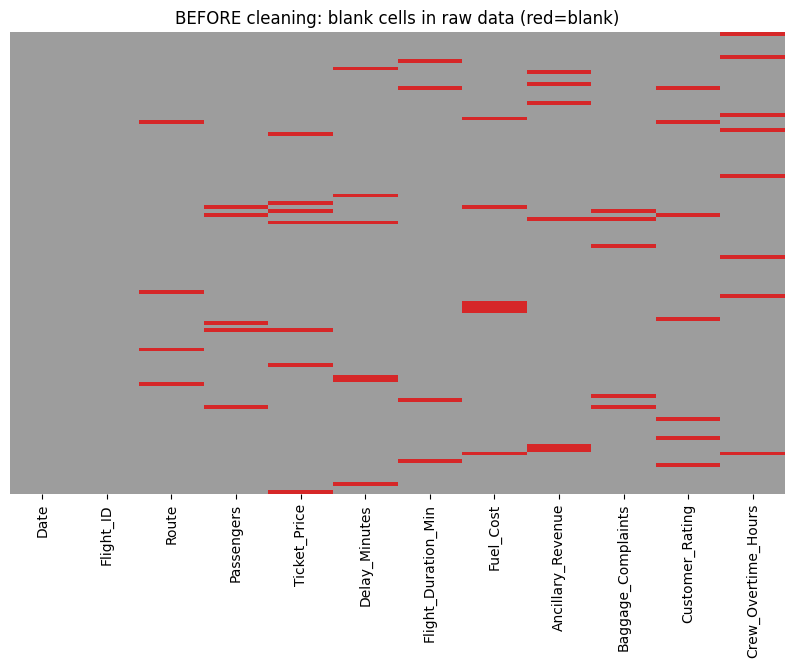

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

colors = ListedColormap(["#9d9d9d", "#d62728"])

plt.figure(figsize=(10,6))
sns.heatmap(raw.isnull(), cmap=colors, cbar=False, yticklabels=False)
plt.title("BEFORE cleaning: blank cells in raw data (red=blank)")
plt.show()

In [ ]:
#Descriptive statistics: spot values that look wrong

In [ ]:
# Redefining num_cols with the correct spellings
num_cols = ["Passengers", "Ticket_Price", "Delay_Minutes", "Flight_Duration_Min", "Fuel_Cost", "Ancillary_Revenue", "Baggage_Complaints", "Customer_Rating", "Crew_Overtime_Hours"]

raw[num_cols].describe().round(1)

,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
count,115.0,113.0,114.0,116.0,114.0,114.0,115.0,113.0,112.0
mean,155.0,6374.3,19.4,157.2,511.2,59615.8,3.1,4.2,6.5
std,13.6,4836.7,35.9,30.0,78.0,11182.3,2.4,0.6,2.8
min,120.0,4800.0,-45.0,122.0,398.0,37900.0,0.0,3.5,2.8
25%,147.0,5550.0,9.0,132.0,433.0,54425.0,2.0,4.0,5.2
50%,155.0,5900.0,16.0,165.0,530.0,58800.0,3.0,4.1,6.1
75%,163.0,6300.0,23.8,170.0,563.8,64225.0,4.0,4.3,7.3
max,215.0,57000.0,380.0,410.0,980.0,148000.0,19.0,9.4,31.5


In [ ]:
# A big gap between mean and median is a warning sign
gap = pd.DataFrame({
    "Mean": raw[num_cols].mean(),
    "Median": raw[num_cols].median()
})

gap["Gap %"] = ((gap["Mean" ] - gap["Median"]) / gap["Median"] * 100).round(1)

gap.round(1)

,Mean,Median,Gap %
Passengers,155.0,155.0,-0.0
Ticket_Price,6374.3,5900.0,8.0
Delay_Minutes,19.4,16.0,21.2
Flight_Duration_Min,157.2,165.0,-4.7
Fuel_Cost,511.2,530.0,-3.5
Ancillary_Revenue,59615.8,58800.0,1.4
Baggage_Complaints,3.1,3.0,3.5
Customer_Rating,4.2,4.1,1.8
Crew_Overtime_Hours,6.5,6.1,6.2


#Step 1 : on missing values- setting up rules for each variables

In [ ]:
import pandas as pd

# Load the dataset to define 'raw'
file_path = '/content/SkyBridge_Airline_Data (1).xlsx'
raw = pd.read_excel(file_path, sheet_name="Unclean_Data")

# step 1 : missing values: setting up rules for each variable
rules = {
    "Passengers": (0, 180),  # aircraft has 180 seats
    "Ticket_Price": (1000, 20000),# domestic low-cost fare in INR
    "Delay_Minutes": (0, 600),# a delay cannot be negative
    "Flight_Duration_Min": (60, 240),# domestic sector
    "Customer_Rating": (1, 5)# rating scale 1 to 5
}

for col, (low, high) in rules.items():
  bad = raw[(raw[col] < low) | (raw[col] > high)]
  print(col, "-> impossible values:", len(bad))
  if len(bad) > 0:
    print(bad[["Date", "Flight_ID", col]].to_string(index=False))
    print()

Passengers -> impossible values: 1
      Date Flight_ID  Passengers
2026-02-07    SB-038       215.0

Ticket_Price -> impossible values: 1
      Date Flight_ID  Ticket_Price
2026-01-15    SB-015       57000.0

Delay_Minutes -> impossible values: 1
      Date Flight_ID  Delay_Minutes
2026-01-23    SB-023          -45.0

Flight_Duration_Min -> impossible values: 1
      Date Flight_ID  Flight_Duration_Min
2026-04-02    SB-092                410.0

Customer_Rating -> impossible values: 1
      Date Flight_ID  Customer_Rating
2026-03-18    SB-077              9.4



#STEP 2 : Time series plot

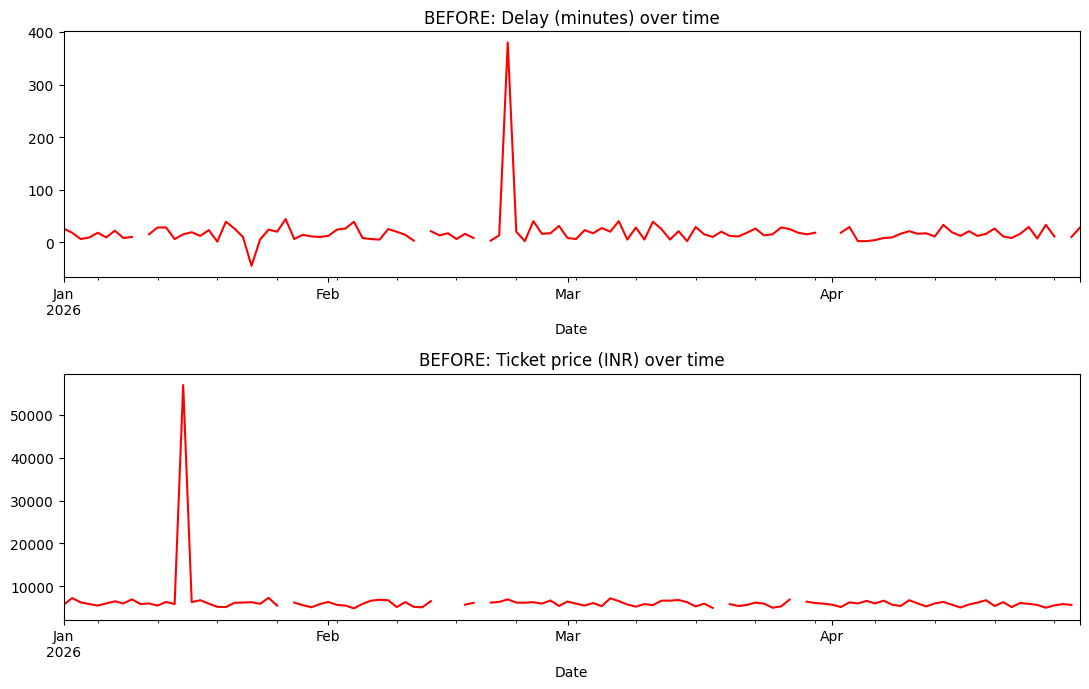

In [ ]:
import matplotlib.pyplot as plt

ts_raw = raw.set_index("Date")

fig, axes = plt.subplots(2, 1, figsize=(11, 7))

ts_raw["Delay_Minutes"].plot(ax=axes[0], color="red", title="BEFORE: Delay (minutes) over time")
ts_raw["Ticket_Price"].plot(ax=axes[1], color="red", title="BEFORE: Ticket price (INR) over time")

plt.tight_layout()
plt.show()

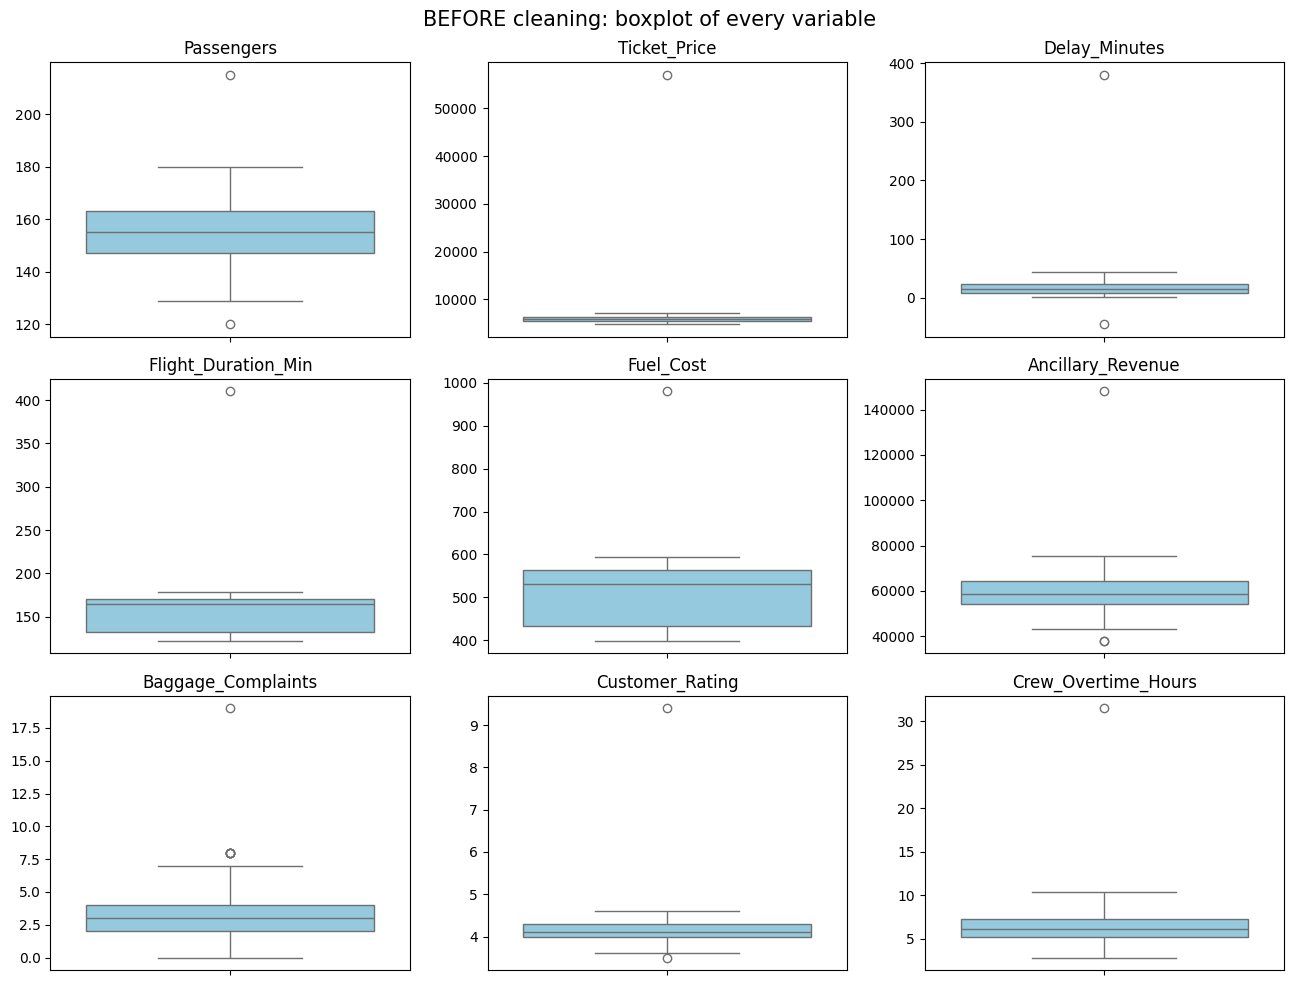

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Define the numeric columns to fix the NameError
num_cols = ["Passengers", "Ticket_Price", "Delay_Minutes", "Flight_Duration_Min", "Fuel_Cost", "Ancillary_Revenue", "Baggage_Complaints", "Customer_Rating", "Crew_Overtime_Hours"]

def show_boxplots(data, title):
    fig, axes = plt.subplots(3, 3, figsize=(13, 10))
    axes = axes.flatten()

    for i, col in enumerate(num_cols):
        sns.boxplot(y=data[col], ax=axes[i], color="skyblue")
        axes[i].set_title(col)
        axes[i].set_ylabel("")

    fig.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.show()

show_boxplots(raw, "BEFORE cleaning: boxplot of every variable")

In [ ]:
# Identify and filter out rows with negative Delay_Minutes
negative_delays = raw[raw["Delay_Minutes"] < 0]
print("Anomalous rows with negative delays:")
display(negative_delays)

# Filter the dataset to keep only non-negative delays (or NaN values)
raw_filtered = raw[(raw["Delay_Minutes"] >= 0) | (raw["Delay_Minutes"].isna())]
print(f"\nOriginal rows: {len(raw)}, Filtered rows: {len(raw_filtered)}")

Anomalous rows with negative delays:


,Date,Flight_ID,Route,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
22,2026-01-23,SB-023,Delhi-Bengaluru,180.0,6250.0,-45.0,164.0,NaN,67700.0,1.0,4.0,8.4



Original rows: 120, Filtered rows: 119


#Step 3: Retaining, Removing and Caping

In [ ]:
raw[raw["Delay_Minutes"] > 100 ]

,Date,Flight_ID,Route,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
52,2026-02-22,SB-053,Delhi-Bengaluru,147.0,6900.0,380.0,173.0,980.0,62500.0,19.0,4.2,31.5


#Step 4: Removing Impossible Values

In [ ]:
import numpy as np

# Create a copy
df = raw.copy()

# Find ratings below 1 or above 5
bad_values = (df["Customer_Rating"] < 1) | (df["Customer_Rating"] > 5)

# Count unusual ratings
print("Unusual ratings:", bad_values.sum())

# Replace unusual ratings with missing values
df.loc[bad_values, "Customer_Rating"] = np.nan

# Compare missing cells
print("Missing cells before:", raw.isnull().sum().sum())

print("Missing cells after:", df.isnull().sum().sum())

Unusual ratings: 1
Missing cells before: 58
Missing cells after: 59


In [ ]:
# Select the variable
col = "Ancillary_Revenue"

# Start with the original, uncapped data
before = raw[col].copy()

# Create a fresh dataset for capping
df_capped = raw.copy()

# Calculate Q1, Q3 and IQR using original data
Q1 = before.quantile(0.25)
Q3 = before.quantile(0.75)
IQR = Q3 - Q1

# Calculate the upper and lower limits
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Apply capping to the new dataset
df_capped[col] = before.clip(lower, upper)

In [ ]:
# Select the variable
col = "Ancillary_Revenue"

# Start with the original, uncapped data
before = raw[col].copy()

# Create a fresh dataset for capping
df_capped = raw.copy()

# Calculate Q1, Q3 and IQR using original data
Q1 = before.quantile(0.25)
Q3 = before.quantile(0.75)
IQR = Q3 - Q1

# Calculate the upper and lower limits
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Apply capping to the new dataset
df_capped[col] = before.clip(lower, upper)

# Count values capped
capped_count = ((before < lower) | (before > upper)).sum()

print("Variable:", col)
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower)
print("Upper limit:", upper)
print("Values capped:", capped_count)

# Compare before and after capping
print("\nBefore capping:")
print(before.describe())

print("\nAfter capping:")
print(df_capped[col].describe())

Variable: Ancillary_Revenue
Q1: 54425.0
Q3: 64225.0
IQR: 9800.0
Lower limit: 39725.0
Upper limit: 78925.0
Values capped: 3

Before capping:
count       114.000000
mean      59615.789474
std       11182.331029
min       37900.000000
25%       54425.000000
50%       58800.000000
75%       64225.000000
max      148000.000000
Name: Ancillary_Revenue, dtype: float64

After capping:
count      114.000000
mean     59040.131579
std       7590.232005
min      39725.000000
25%      54425.000000
50%      58800.000000
75%      64225.000000
max      78925.000000
Name: Ancillary_Revenue, dtype: float64


Maximum before: 148000.0
Maximum after: 78925.0
Upper limit: 78925.0


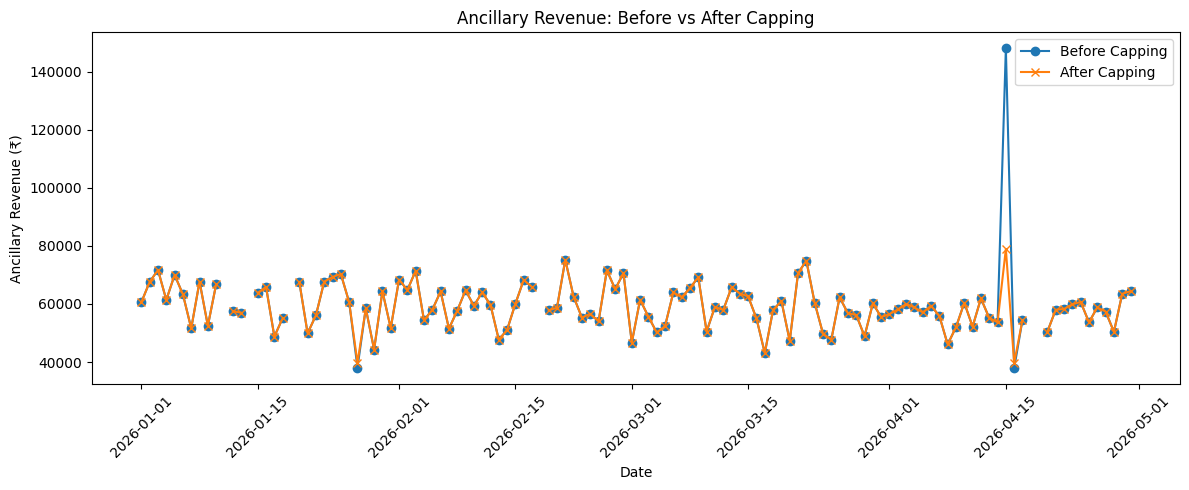

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Select the variable
col = "Ancillary_Revenue"

# Start with the original, uncapped data
before = raw[col].copy()

# Create a fresh dataset for capping
df_capped = raw.copy()

# Calculate Q1, Q3 and IQR using original data
Q1 = before.quantile(0.25)
Q3 = before.quantile(0.75)
IQR = Q3 - Q1

# Calculate the upper and lower limits
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Apply capping to the new dataset
df_capped[col] = before.clip(lower, upper)

# Print maximum values
print("Maximum before:", before.max())
print("Maximum after:", df_capped[col].max())
print("Upper limit:", upper)

# Plot before and after
plt.figure(figsize=(12, 5))

plt.plot(raw["Date"], before,
         label="Before Capping", marker="o")

plt.plot(raw["Date"], df_capped[col],
         label="After Capping", marker="x")

plt.title("Ancillary Revenue: Before vs After Capping")
plt.xlabel("Date")
plt.ylabel("Ancillary Revenue (₹)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#LECTURE 8


flagged by IQR but possible

In [ ]:
# Examples we keep: 120 passengers on a quiet day, baggage complaints of 8, the fog-day values
import pandas as pd

# Load the dataset directly to ensure 'raw' and 'df' are defined
file_path = '/content/SkyBridge_Airline_Data (1).xlsx'
raw = pd.read_excel(file_path, sheet_name="Unclean_Data")
df = raw

df[(df["Passengers"] < 125) | (df["Baggage_Complaints"] >= 8) | (df["Delay_Minutes"] > 100)][
    ["Date", "Passengers", "Delay_Minutes", "Baggage_Complaints"]
]

,Date,Passengers,Delay_Minutes,Baggage_Complaints
26,2026-01-27,120.0,44.0,2.0
33,2026-02-03,169.0,26.0,8.0
52,2026-02-22,147.0,380.0,19.0
63,2026-03-05,167.0,27.0,8.0
76,2026-03-18,157.0,10.0,8.0
104,2026-04-15,143.0,19.0,8.0
109,2026-04-20,143.0,26.0,8.0


In [ ]:
# Examples we keep: 120 passengers on a quiet day, baggage complaints of 8, the fog-day values
import pandas as pd

# Load the dataset directly to ensure 'raw' and 'df' are defined
file_path = '/content/SkyBridge_Airline_Data (1).xlsx'
raw = pd.read_excel(file_path, sheet_name="Unclean_Data")
df = raw

df[(df["Passengers"] < 125) | (df["Baggage_Complaints"] >= 8) | (df["Delay_Minutes"] > 100)][
    ["Date", "Passengers", "Delay_Minutes", "Baggage_Complaints"]
]

,Date,Passengers,Delay_Minutes,Baggage_Complaints
26,2026-01-27,120.0,44.0,2.0
33,2026-02-03,169.0,26.0,8.0
52,2026-02-22,147.0,380.0,19.0
63,2026-03-05,167.0,27.0,8.0
76,2026-03-18,157.0,10.0,8.0
104,2026-04-15,143.0,19.0,8.0
109,2026-04-20,143.0,26.0,8.0


In [ ]:
# Method 1: Remove rows containing missing values
df_drop = df.dropna()

# Show descriptive statistics before removing missing values
print("DESCRIPTIVE STATISTICS BEFORE dropna()")
display(df.describe().round(2))

# Show descriptive statistics after removing missing values
print("DESCRIPTIVE STATISTICS AFTER dropna()")
display(df_drop.describe().round(2))

# Compare the number of rows
print("Rows before:", len(df))
print("Rows after :", len(df_drop))

# Calculate percentage of data lost
print("Data lost:", round((1 - len(df_drop) / len(df)) * 100, 1), "%")

DESCRIPTIVE STATISTICS BEFORE dropna()


,Date,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
count,120,115.00,113.00,114.00,116.00,114.00,114.00,115.00,113.00,112.00
mean,2026-03-01 12:00:00,154.96,6374.34,19.39,157.19,511.22,59615.79,3.10,4.17,6.48
min,2026-01-01 00:00:00,120.00,4800.00,-45.00,122.00,398.00,37900.00,0.00,3.50,2.80
25%,2026-01-30 18:00:00,147.00,5550.00,9.00,132.00,433.00,54425.00,2.00,4.00,5.20
50%,2026-03-01 12:00:00,155.00,5900.00,16.00,165.00,530.00,58800.00,3.00,4.10,6.10
75%,2026-03-31 06:00:00,163.00,6300.00,23.75,170.00,563.75,64225.00,4.00,4.30,7.30
max,2026-04-30 00:00:00,215.00,57000.00,380.00,410.00,980.00,148000.00,19.00,9.40,31.50
std,NaN,13.61,4836.71,35.89,30.01,78.03,11182.33,2.41,0.56,2.81


DESCRIPTIVE STATISTICS AFTER dropna()


,Date,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
count,72,72.00,72.00,72.00,72.00,72.00,72.00,72.00,72.00,72.00
mean,2026-02-28 04:20:00,155.51,5950.69,22.25,154.06,512.28,60787.50,3.22,4.21,6.72
min,2026-01-02 00:00:00,129.00,4800.00,2.00,122.00,398.00,44300.00,0.00,3.60,3.90
25%,2026-01-31 18:00:00,148.75,5537.50,10.00,132.00,433.00,55175.00,2.00,4.00,5.18
50%,2026-02-28 00:00:00,156.00,5950.00,17.00,165.00,530.00,59200.00,3.00,4.10,6.30
75%,2026-03-27 12:00:00,161.25,6300.00,24.25,169.00,563.25,64325.00,4.00,4.30,7.45
max,2026-04-29 00:00:00,180.00,7250.00,380.00,179.00,980.00,148000.00,19.00,9.40,31.50
std,NaN,11.38,584.57,43.82,18.84,85.13,12568.81,2.78,0.66,3.33


Rows before: 120
Rows after : 72
Data lost: 40.0 %


In [ ]:
# Method 1: Remove rows containing missing values
df_drop = df.dropna()

# Show descriptive statistics before removing missing values
print("DESCRIPTIVE STATISTICS BEFORE dropna()")
display(df.describe().round(2))

# Show descriptive statistics after removing missing values
print("DESCRIPTIVE STATISTICS AFTER dropna()")
display(df_drop.describe().round(2))

# Compare the number of rows
print("Rows before:", len(df))
print("Rows after :", len(df_drop))

# Calculate percentage of data lost
print("Data lost:", round((1 - len(df_drop) / len(df)) * 100, 1), "%")

# Check missing values in each column after dropna()
print("Missing values after dropna():")
print(df_drop.isnull().sum())

# Count all missing cells in the dataset
print("Total blank cells:", df_drop.isnull().sum().sum())

DESCRIPTIVE STATISTICS BEFORE dropna()


,Date,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
count,120,115.00,113.00,114.00,116.00,114.00,114.00,115.00,113.00,112.00
mean,2026-03-01 12:00:00,154.96,6374.34,19.39,157.19,511.22,59615.79,3.10,4.17,6.48
min,2026-01-01 00:00:00,120.00,4800.00,-45.00,122.00,398.00,37900.00,0.00,3.50,2.80
25%,2026-01-30 18:00:00,147.00,5550.00,9.00,132.00,433.00,54425.00,2.00,4.00,5.20
50%,2026-03-01 12:00:00,155.00,5900.00,16.00,165.00,530.00,58800.00,3.00,4.10,6.10
75%,2026-03-31 06:00:00,163.00,6300.00,23.75,170.00,563.75,64225.00,4.00,4.30,7.30
max,2026-04-30 00:00:00,215.00,57000.00,380.00,410.00,980.00,148000.00,19.00,9.40,31.50
std,NaN,13.61,4836.71,35.89,30.01,78.03,11182.33,2.41,0.56,2.81


DESCRIPTIVE STATISTICS AFTER dropna()


,Date,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
count,72,72.00,72.00,72.00,72.00,72.00,72.00,72.00,72.00,72.00
mean,2026-02-28 04:20:00,155.51,5950.69,22.25,154.06,512.28,60787.50,3.22,4.21,6.72
min,2026-01-02 00:00:00,129.00,4800.00,2.00,122.00,398.00,44300.00,0.00,3.60,3.90
25%,2026-01-31 18:00:00,148.75,5537.50,10.00,132.00,433.00,55175.00,2.00,4.00,5.18
50%,2026-02-28 00:00:00,156.00,5950.00,17.00,165.00,530.00,59200.00,3.00,4.10,6.30
75%,2026-03-27 12:00:00,161.25,6300.00,24.25,169.00,563.25,64325.00,4.00,4.30,7.45
max,2026-04-29 00:00:00,180.00,7250.00,380.00,179.00,980.00,148000.00,19.00,9.40,31.50
std,NaN,11.38,584.57,43.82,18.84,85.13,12568.81,2.78,0.66,3.33


Rows before: 120
Rows after : 72
Data lost: 40.0 %
Missing values after dropna():
Date                   0
Flight_ID              0
Route                  0
Passengers             0
Ticket_Price           0
Delay_Minutes          0
Flight_Duration_Min    0
Fuel_Cost              0
Ancillary_Revenue      0
Baggage_Complaints     0
Customer_Rating        0
Crew_Overtime_Hours    0
dtype: int64
Total blank cells: 0


In [ ]:
# Create a copy of the original dataset
df_mean = df.copy()

# Define the list of numeric columns to fix the NameError
num_cols = ["Passengers", "Ticket_Price", "Delay_Minutes", "Flight_Duration_Min", "Fuel_Cost", "Ancillary_Revenue", "Baggage_Complaints", "Customer_Rating", "Crew_Overtime_Hours"]

# Display descriptive statistics BEFORE filling missing values
print("DESCRIPTIVE STATISTICS BEFORE IMPUTATION")
display(df.describe().round(2))

# Fill missing values in numeric columns using the mean
df_mean[num_cols] = df_mean[num_cols].fillna(df_mean[num_cols].mean())

# Fill missing Route values using the most common route (mode)
df_mean["Route"] = df_mean["Route"].fillna(df_mean["Route"].mode()[0])

# Display descriptive statistics AFTER filling missing values
print("DESCRIPTIVE STATISTICS AFTER MEAN AND MODE IMPUTATION")
display(df_mean.describe().round(2))

# Compare the number of rows before and after
print("Rows before:", len(df))
print("Rows after :", len(df_mean))

# Count missing cells remaining after imputation
print("Blanks left:", df_mean.isnull().sum().sum())

DESCRIPTIVE STATISTICS BEFORE IMPUTATION


,Date,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
count,120,115.00,113.00,114.00,116.00,114.00,114.00,115.00,113.00,112.00
mean,2026-03-01 12:00:00,154.96,6374.34,19.39,157.19,511.22,59615.79,3.10,4.17,6.48
min,2026-01-01 00:00:00,120.00,4800.00,-45.00,122.00,398.00,37900.00,0.00,3.50,2.80
25%,2026-01-30 18:00:00,147.00,5550.00,9.00,132.00,433.00,54425.00,2.00,4.00,5.20
50%,2026-03-01 12:00:00,155.00,5900.00,16.00,165.00,530.00,58800.00,3.00,4.10,6.10
75%,2026-03-31 06:00:00,163.00,6300.00,23.75,170.00,563.75,64225.00,4.00,4.30,7.30
max,2026-04-30 00:00:00,215.00,57000.00,380.00,410.00,980.00,148000.00,19.00,9.40,31.50
std,NaN,13.61,4836.71,35.89,30.01,78.03,11182.33,2.41,0.56,2.81


DESCRIPTIVE STATISTICS AFTER MEAN AND MODE IMPUTATION


,Date,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
count,120,120.00,120.00,120.00,120.00,120.00,120.00,120.00,120.00,120.00
mean,2026-03-01 12:00:00,154.96,6374.34,19.39,157.19,511.22,59615.79,3.10,4.17,6.48
min,2026-01-01 00:00:00,120.00,4800.00,-45.00,122.00,398.00,37900.00,0.00,3.50,2.80
25%,2026-01-30 18:00:00,147.00,5587.50,9.75,132.75,433.75,54875.00,2.00,4.00,5.28
50%,2026-03-01 12:00:00,154.96,5950.00,16.00,165.00,529.50,59400.00,3.00,4.17,6.30
75%,2026-03-31 06:00:00,162.25,6356.08,23.00,169.25,563.00,64000.00,4.00,4.30,7.22
max,2026-04-30 00:00:00,215.00,57000.00,380.00,410.00,980.00,148000.00,19.00,9.40,31.50
std,NaN,13.32,4692.30,34.97,29.50,76.04,10896.78,2.36,0.54,2.71


Rows before: 120
Rows after : 120
Blanks left: 0


In [ ]:
# Create a copy of the original dataset
df_mean = df.copy()

# Display descriptive statistics BEFORE filling missing values
print("DESCRIPTIVE STATISTICS BEFORE IMPUTATION")
display(df.describe().round(2))

# Fill missing values in numeric columns using the mean
df_mean[num_cols] = df_mean[num_cols].fillna(df_mean[num_cols].mean())

# Fill missing Route values using the most common route (mode)
df_mean["Route"] = df_mean["Route"].fillna(df_mean["Route"].mode()[0])

# Display descriptive statistics AFTER filling missing values
print("DESCRIPTIVE STATISTICS AFTER MEAN AND MODE IMPUTATION")
display(df_mean.describe().round(2))

# Compare the number of rows before and after
print("Rows before:", len(df))
print("Rows after :", len(df_mean))

# Count missing cells remaining after imputation
print("Blanks left:", df_mean.isnull().sum().sum())

DESCRIPTIVE STATISTICS BEFORE IMPUTATION


,Date,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
count,120,115.00,113.00,114.00,116.00,114.00,114.00,115.00,113.00,112.00
mean,2026-03-01 12:00:00,154.96,6374.34,19.39,157.19,511.22,59615.79,3.10,4.17,6.48
min,2026-01-01 00:00:00,120.00,4800.00,-45.00,122.00,398.00,37900.00,0.00,3.50,2.80
25%,2026-01-30 18:00:00,147.00,5550.00,9.00,132.00,433.00,54425.00,2.00,4.00,5.20
50%,2026-03-01 12:00:00,155.00,5900.00,16.00,165.00,530.00,58800.00,3.00,4.10,6.10
75%,2026-03-31 06:00:00,163.00,6300.00,23.75,170.00,563.75,64225.00,4.00,4.30,7.30
max,2026-04-30 00:00:00,215.00,57000.00,380.00,410.00,980.00,148000.00,19.00,9.40,31.50
std,NaN,13.61,4836.71,35.89,30.01,78.03,11182.33,2.41,0.56,2.81


DESCRIPTIVE STATISTICS AFTER MEAN AND MODE IMPUTATION


,Date,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
count,120,120.00,120.00,120.00,120.00,120.00,120.00,120.00,120.00,120.00
mean,2026-03-01 12:00:00,154.96,6374.34,19.39,157.19,511.22,59615.79,3.10,4.17,6.48
min,2026-01-01 00:00:00,120.00,4800.00,-45.00,122.00,398.00,37900.00,0.00,3.50,2.80
25%,2026-01-30 18:00:00,147.00,5587.50,9.75,132.75,433.75,54875.00,2.00,4.00,5.28
50%,2026-03-01 12:00:00,154.96,5950.00,16.00,165.00,529.50,59400.00,3.00,4.17,6.30
75%,2026-03-31 06:00:00,162.25,6356.08,23.00,169.25,563.00,64000.00,4.00,4.30,7.22
max,2026-04-30 00:00:00,215.00,57000.00,380.00,410.00,980.00,148000.00,19.00,9.40,31.50
std,NaN,13.32,4692.30,34.97,29.50,76.04,10896.78,2.36,0.54,2.71


Rows before: 120
Rows after : 120
Blanks left: 0


#Method 3: Mode

In [ ]:
df_mode = df.copy()

for col in df_mode.columns:
    df_mode[col] = df_mode[col].fillna(df_mode[col].mode()[0])

print("Blanks left:", df_mode.isnull().sum().sum())

Blanks left: 0


#Method 4: Median

In [ ]:
df_median = df.copy()

df_median[num_cols] = df_median[num_cols].fillna(df_median[num_cols].median())

# Route is text, so use the most common route
df_median["Route"] = df_median["Route"].fillna(df_median["Route"].mode()[0])

print("Blanks left:", df_median.isnull().sum().sum())

Blanks left: 0


#Heatplot after treatment

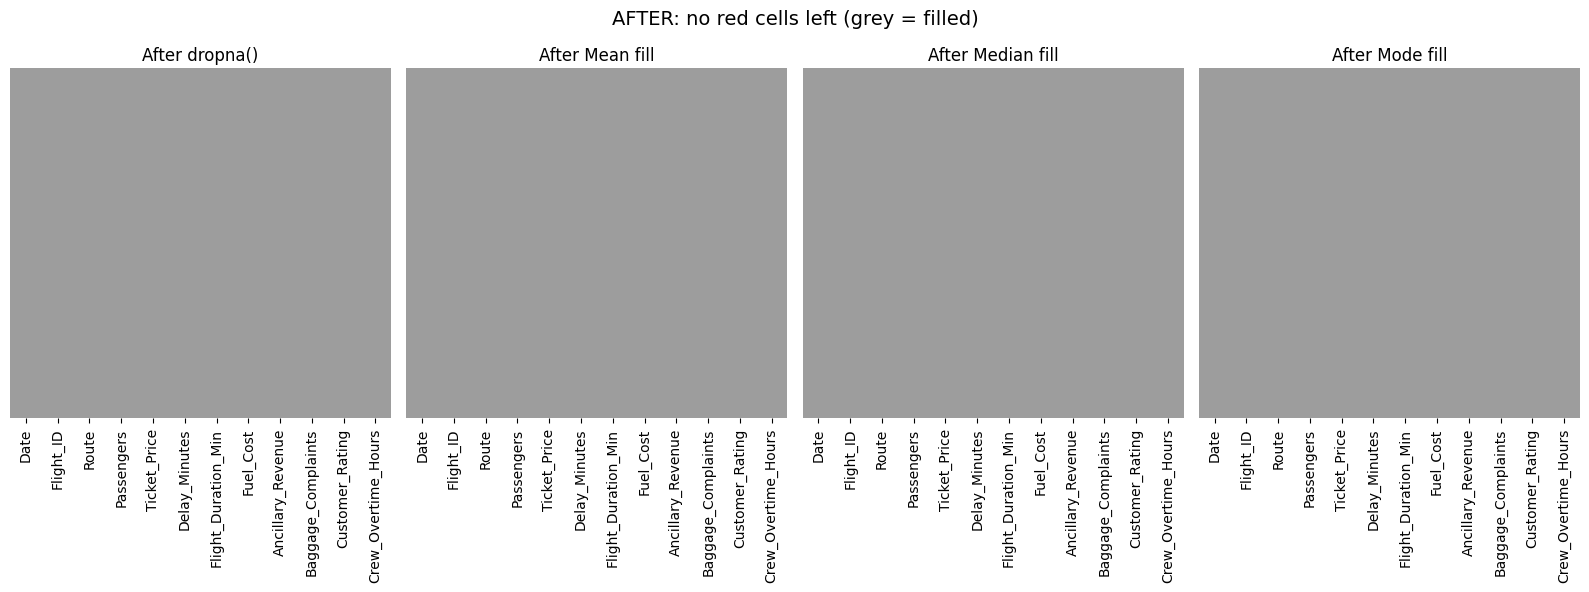

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

# Define the color map used for missing values (grey for filled, red for blank)
colors = ListedColormap(["#9d9d9d", "#d62728"])

fig, axes = plt.subplots(1, 4, figsize=(16, 6))

sns.heatmap(df_drop.isnull(), cmap=colors, cbar=False, yticklabels=False, ax=axes[0])
axes[0].set_title("After dropna()")

sns.heatmap(df_mean.isnull(), cmap=colors, cbar=False, yticklabels=False, ax=axes[1])
axes[1].set_title("After Mean fill")

sns.heatmap(df_median.isnull(), cmap=colors, cbar=False, yticklabels=False, ax=axes[2])
axes[2].set_title("After Median fill")

sns.heatmap(df_mode.isnull(), cmap=colors, cbar=False, yticklabels=False, ax=axes[3])
axes[3].set_title("After Mode fill")

plt.suptitle("AFTER: no red cells left (grey = filled)", fontsize=14)
plt.tight_layout()
plt.show()

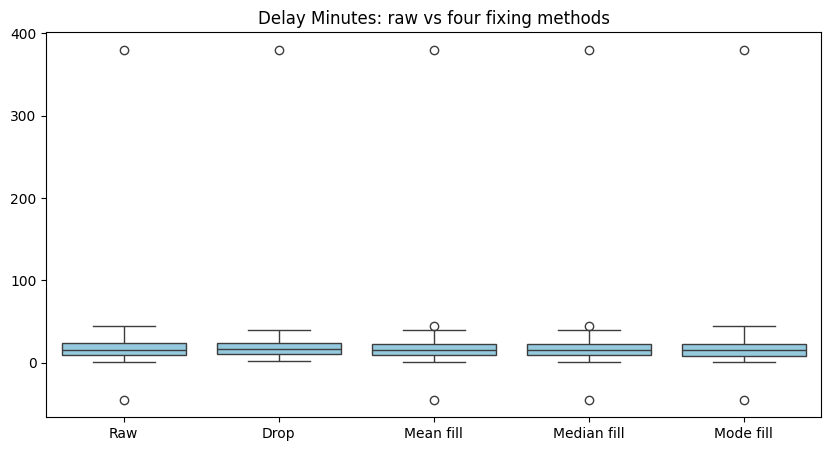

52     380.0
26      44.0
65      40.0
55      40.0
19      39.0
34      39.0
69      39.0
115     33.0
103     33.0
58      31.0
Name: Delay_Minutes, dtype: float64


In [ ]:
# Boxplot of Delay_Minutes: raw versus the four methods

delay_compare = pd.DataFrame({
    "Raw": raw["Delay_Minutes"],
    "Drop": df_drop["Delay_Minutes"],
    "Mean fill": df_mean["Delay_Minutes"],
    "Median fill": df_median["Delay_Minutes"],
    "Mode fill": df_mode["Delay_Minutes"]
})

plt.figure(figsize=(10, 5))
sns.boxplot(data=delay_compare, color="skyblue")
plt.title("Delay Minutes: raw vs four fixing methods")
plt.show()

# Check the largest delay values
print(
    raw["Delay_Minutes"]
    .sort_values(ascending=False)
    .head(10)
)

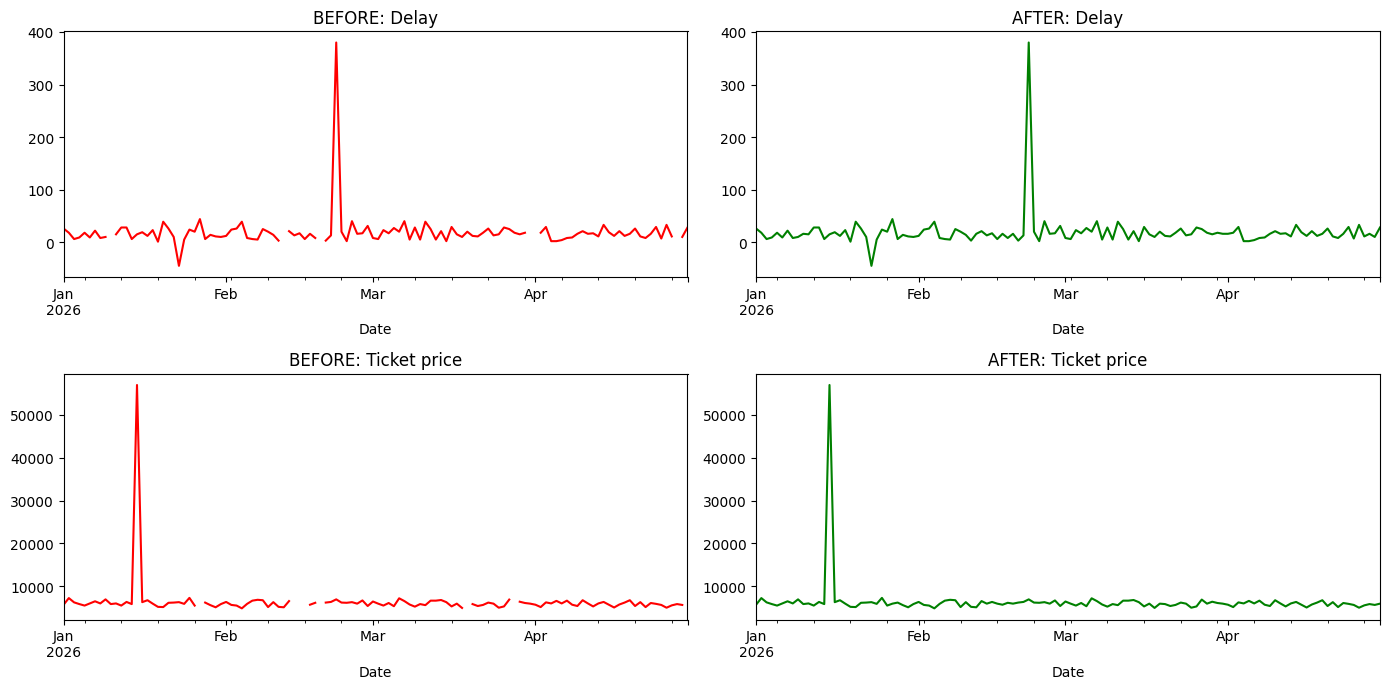

In [ ]:
# BEFORE vs AFTER: time series
import matplotlib.pyplot as plt

# Define the final cleaned/imputed dataset to compare (e.g., df_median or df_mean)
final = df_median

ts_raw = raw.set_index("Date")
ts_final = final.set_index("Date")

fig, axes = plt.subplots(2, 2, figsize=(14, 7))

ts_raw["Delay_Minutes"].plot(
    ax=axes[0, 0],
    color="red",
    title="BEFORE: Delay"
)

ts_final["Delay_Minutes"].plot(
    ax=axes[0, 1],
    color="green",
    title="AFTER: Delay"
)

ts_raw["Ticket_Price"].plot(
    ax=axes[1, 0],
    color="red",
    title="BEFORE: Ticket price"
)

ts_final["Ticket_Price"].plot(
    ax=axes[1, 1],
    color="green",
    title="AFTER: Ticket price"
)

plt.tight_layout()
plt.show()

#Lecture 9-10

#Advance Data Visuals.

In [1]:
import pandas as pd
import numpy as np

df = pd.read_excel("Zepto_Orders_Data (1).xlsx", sheet_name="Orders")

print("Rows:", df.shape[0], "| Columns:", df.shape[1])
df.head()

Rows: 1200 | Columns: 14


,Order_ID,Order_Date,Time_Slot,State,City,Category,Customer_Type,Weather,Distance_KM,Basket_Size,Order_Value,Discount_Pct,Delivery_Time_Min,Customer_Rating
0,ZP-0001,2026-07-01,Afternoon,Haryana,Gurugram,Snacks & Drinks,Pass Member,Clear,1.1,7,755,18,9,4.9
1,ZP-0002,2026-07-01,Evening,Tamil Nadu,Chennai,Household Items,Pass Member,Clear,1.9,5,835,0,8,5.0
2,ZP-0003,2026-07-01,Afternoon,NCT of Delhi,Delhi,Dairy & Bread,Pass Member,Clear,0.3,5,605,20,9,4.7
3,ZP-0004,2026-07-01,Late Night,Uttar Pradesh,Noida,Snacks & Drinks,Pass Member,Clear,3.7,5,420,20,19,4.5
4,ZP-0005,2026-07-01,Evening,Kerala,Kochi,Dairy & Bread,New User,Clear,0.5,10,670,39,8,5.0


#Descriptive Statistics

In [3]:
#Number of orderin a particualar state
df["State"].value_counts()

,count
State,
Karnataka,223
NCT of Delhi,188
Maharashtra,182
Telangana,113
Haryana,107
Tamil Nadu,107
Uttar Pradesh,94
Gujarat,55
West Bengal,54


In [4]:
#Consitence of dates

In [5]:
# Step 3 | Prepare helper columns

df["Week"] = df["Order_Date"].dt.isocalendar().week.astype(int)
df["Weekday"] = df["Order_Date"].dt.day_name()
df["Within_10_Min"] = df["Delivery_Time_Min"] <= 10  # True if we kept the promise

# Fixed orders so charts always show groups in a sensible order
slot_order = ["Morning", "Afternoon", "Evening", "Late Night"]
type_order = ["New User", "Regular", "Pass Member"]

df[["Order_Date", "Week", "Weekday", "Within_10_Min"]].head()

,Order_Date,Week,Weekday,Within_10_Min
0,2026-07-01,27,Wednesday,True
1,2026-07-01,27,Wednesday,True
2,2026-07-01,27,Wednesday,True
3,2026-07-01,27,Wednesday,False
4,2026-07-01,27,Wednesday,True


#Matplotlib - How long does it take the delivery take and many are inside the promise.

In [6]:
import matplotlib.pyplot as plt


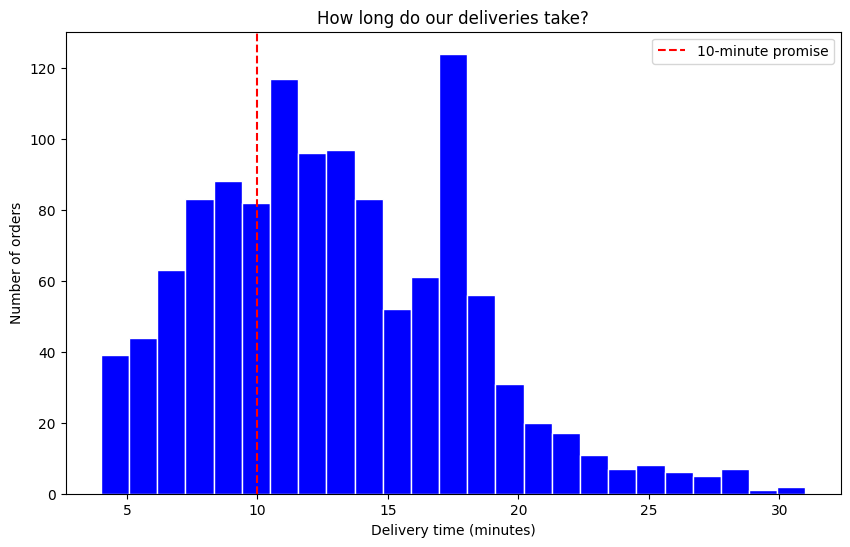

In [7]:
import matplotlib.pyplot as plt
import pandas as pd

# Ensure delivery time is numeric
df["Delivery_Time_Min"] = pd.to_numeric(
    df["Delivery_Time_Min"], errors="coerce"
)

# Create histogram
plt.figure(figsize=(10, 6))

plt.hist(df["Delivery_Time_Min"].dropna(),
         bins=25, color="blue", edgecolor="white")

plt.axvline(10, color="red", linestyle="--",
            label="10-minute promise")

plt.title("How long do our deliveries take?")
plt.xlabel("Delivery time (minutes)")
plt.ylabel("Number of orders")
plt.legend()
plt.show()

#Which product category brings the most sale

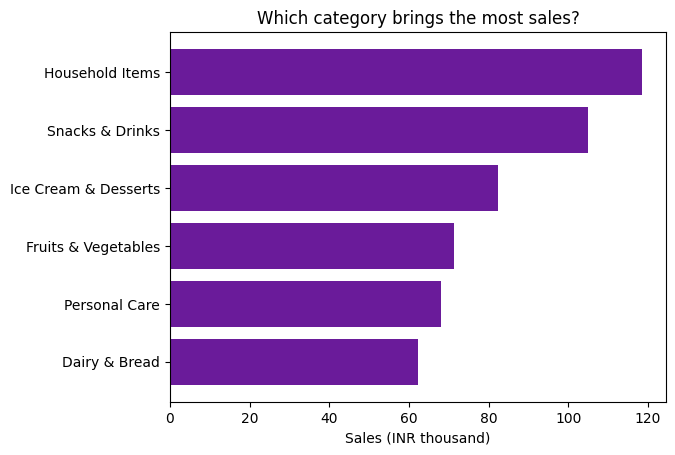

In [8]:
category_sales = df.groupby("Category")["Order_Value"].sum().sort_values()

plt.barh(category_sales.index, category_sales.values / 1000, color="#6A1B9A")
plt.title("Which category brings the most sales?")
plt.xlabel("Sales (INR thousand)")
plt.show()

#Are orders growing week by week

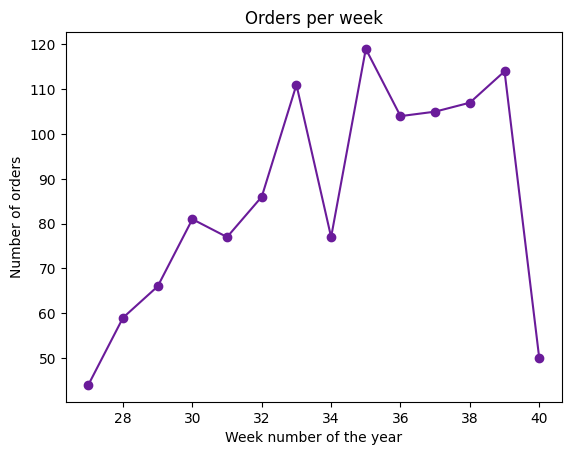

In [9]:
weekly_orders = df.groupby("Week")["Order_ID"].count()

plt.plot(weekly_orders.index, weekly_orders.values, marker="o", color="#6A1B9A")
plt.title("Orders per week")
plt.xlabel("Week number of the year")
plt.ylabel("Number of orders")
plt.show()

#AREA PLOT

#Which part of the day builds our weekly sales.

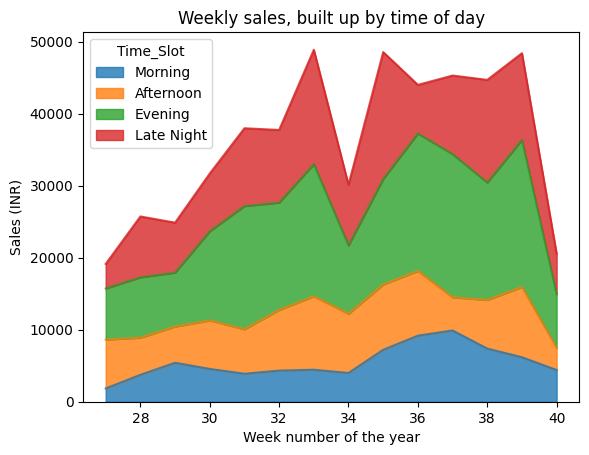

In [10]:
week_slot = df.pivot_table(index="Week", columns="Time_Slot", values="Order_Value", aggfunc="sum")[slot_order]

week_slot.plot(kind="area", alpha=0.8)
plt.title("Weekly sales, built up by time of day")
plt.xlabel("Week number of the year")
plt.ylabel("Sales (INR)")
plt.show()

#Does a longer distance mean a slower delivery, and does a slow delivery mean a lower rating.

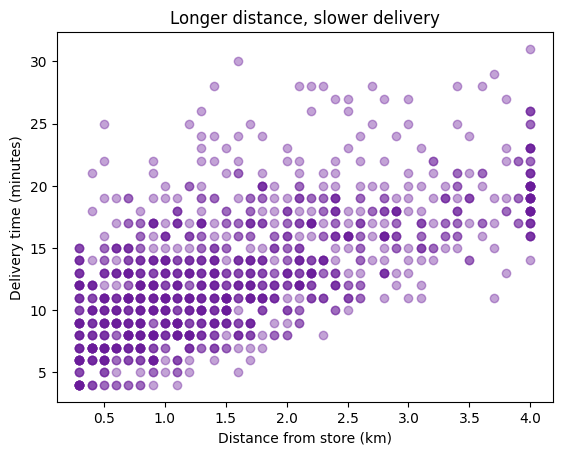

In [11]:
plt.scatter(df["Distance_KM"], df["Delivery_Time_Min"], alpha=0.4, color="#6A1B9A")
plt.title("Longer distance, slower delivery")
plt.xlabel("Distance from store (km)")
plt.ylabel("Delivery time (minutes)")
plt.show()

#Delivery time vs Distance

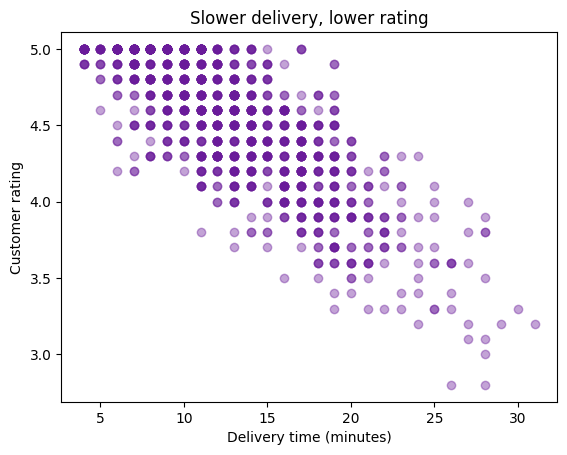

In [12]:
plt.scatter(df["Delivery_Time_Min"], df["Customer_Rating"], alpha=0.4, color="#6A1B9A")
plt.title("Slower delivery, lower rating")
plt.xlabel("Delivery time (minutes)")
plt.ylabel("Customer rating")
plt.show()

#Quiver plot

In [13]:
means = df.groupby(["State", "Weather"])[["Delivery_Time_Min", "Customer_Rating"]].mean().reset_index()

clear = means[means["Weather"] == "Clear"].set_index("State")
rain  = means[means["Weather"] == "Rain"].set_index("State")

x  = clear["Delivery_Time_Min"]                          # arrow starts here (clear weather)
y  = clear["Customer_Rating"]
dx = rain["Delivery_Time_Min"] - clear["Delivery_Time_Min"]   # how far rain moves it
dy = rain["Customer_Rating"] - clear["Customer_Rating"]

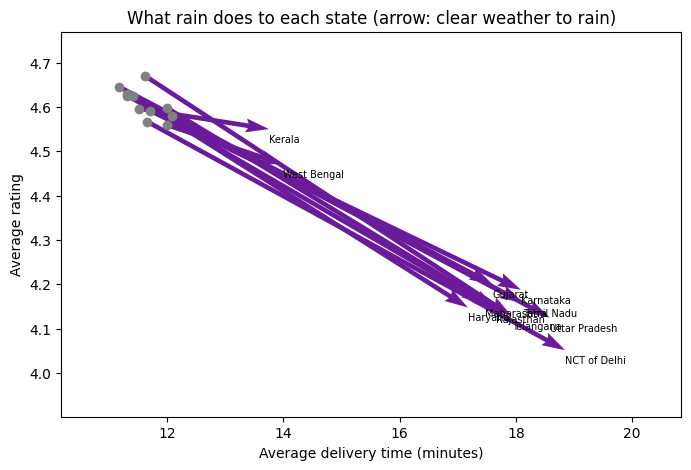

In [14]:
plt.figure(figsize=(8, 5))
plt.quiver(x, y, dx, dy, angles="xy", scale_units="xy", scale=1, color="#6A1B9A")
plt.scatter(x, y, color="grey")

for name in clear.index:
    plt.text(x[name] + dx[name], y[name] + dy[name] - 0.03, name, fontsize=7)   # label at the arrow tip

plt.xlim(x.min() - 1, (x + dx).max() + 2)
plt.ylim((y + dy).min() - 0.15, y.max() + 0.1)
plt.title("What rain does to each state (arrow: clear weather to rain)")
plt.xlabel("Average delivery time (minutes)")
plt.ylabel("Average rating")
plt.show()

#CONTOUR plots/2D plots
#step 1- Developing matrix

In [15]:
# A tiny example first
distance = np.array([1, 2, 3])
basket   = np.array([5, 10])

D, B = np.meshgrid(distance, basket)

print(D)
print(B)

[[1 2 3]
 [1 2 3]]
[[ 5  5  5]
 [10 10 10]]


#Step 2- Dividing Matrix

In [16]:
dist_values   = np.linspace(0.3, 4, 40)     # 40 distances, 0.3 to 4 km
basket_values = np.linspace(1, 12, 40)      # 40 basket sizes, 1 to 12 items

D, B = np.meshgrid(dist_values, basket_values)

print("Number of what-if cases:", D.size)

Number of what-if cases: 1600


#Step 3- Linear regressions / predictions

In [17]:
# A simple formula from our data: delivery time from distance and basket size

from sklearn.linear_model import LinearRegression

formula = LinearRegression().fit(
    df[["Distance_KM", "Basket_Size"]],
    df["Delivery_Time_Min"]
)

print("Each extra km adds about", round(formula.coef_[0], 1), "minutes")
print("Each extra item adds about", round(formula.coef_[1], 2), "minutes")

Each extra km adds about 3.1 minutes
Each extra item adds about 0.31 minutes


#Step 4- What-if case

In [18]:
# Fill every what-if case with the expected delivery time
cases = pd.DataFrame({
    "Distance_KM": D.ravel(),
    "Basket_Size": B.ravel()
})

T = formula.predict(cases).reshape(D.shape)

#How far can a store deliver,for a given basket,and still keeo the 10-mins promise?

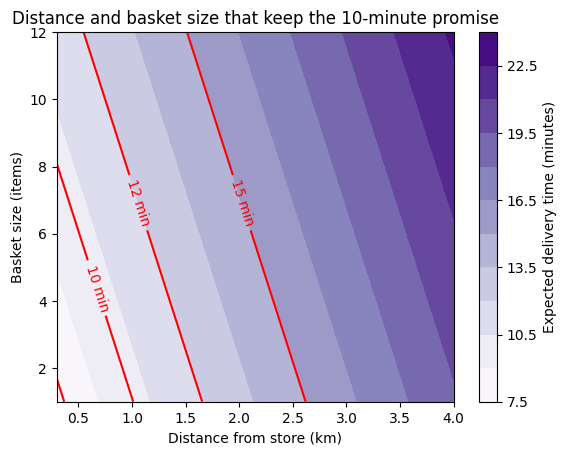

In [19]:
plt.contourf(D, B, T, levels=10, cmap="Purples")
plt.colorbar(label="Expected delivery time (minutes)")

lines = plt.contour(D, B, T, levels=[8, 10, 12, 15], colors="red")
plt.clabel(lines, fmt="%d min")

plt.title("Distance and basket size that keep the 10-minute promise")
plt.xlabel("Distance from store (km)")
plt.ylabel("Basket size (items)")
plt.show()